<a href="https://colab.research.google.com/github/diosthenes/langevin-dynamics/blob/main/Langevin_Dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import truncnorm

In [ ]:
#Particle and Simulation Parameters
x = np.linspace(-10, 10, 1000)
n = 100
x_particles = np.full(n, 5) #initial particle position at x=5
t_start = 0
t_stop = 10000
dt = 0.01
n_steps = int((t_stop - t_start)/dt)

In [ ]:
#Physical Parameters
gamma = 1.0
kB = 1.0
k_potential = 1.0
a_temperature = 12.5
T_1 = 100
T_2 = 200
c_temperature = (T_1 + T_2)/2

In [ ]:
#Potential
def potential(x):
  V = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [lambda x: (x+5)**2, k_potential, lambda x: (x-5)**2])
  return V

In [ ]:
#Temperature function
def Temperature(x):
  T = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [T_1, lambda x:(a_temperature * x) + c_temperature, T_2])
  return T

In [ ]:
#External Force due to the potential
def dV_dx(x):
  F = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [lambda x: 2*(x+5), 0, lambda x: 2*(x-5)])
  return F

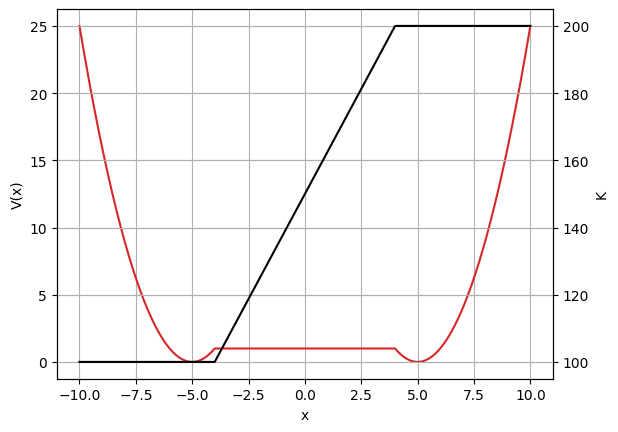

In [ ]:
#Potential and Temperature Visualisation
fig, ax1 = plt.subplots()
#Potential
color = 'tab:red'
ax1.plot(x, potential(x), color=color, label='Potential')
ax1.set_xlabel('x')
ax1.set_ylabel('V(x)')
plt.grid()
#Temperature
ax2 = ax1.twinx()
color = 'black'
ax2.plot(x, Temperature(x), color=color, label='Temperature Function')
ax2.set_ylabel('K')
plt.grid()
plt.show()

In [ ]:
#Euler-Maruyama Integration
for i in range(n_steps):
  T = Temperature(x_particles)
  noise_amp = np.sqrt((2*kB*T)/gamma)
  N_noise = np.random.randn(n)
  F_pot = (-1/gamma) * dV_dx(x_particles) * dt
  N_t = noise_amp * N_noise * np.sqrt(dt)

  x_particles = x_particles + F_pot + N_t

print(x_particles)

[ -3.2018791   -9.26046977  -9.5377498  -10.66876621  13.70650941
  -6.57625298  -1.66652388 -11.98356674 -18.83522899  -7.38178089
  -8.23699921  -7.84382302 -14.95578134  -5.47708441  -1.67756924
  -5.28972991   1.18575505  18.72142108 -15.39392954  -6.05936176
 -10.6127991    6.3288259   -1.78094987 -19.75449235  -0.86825579
   9.27047254  19.23315782  -9.94501936  -7.16878016  12.03202244
 -20.18985291  -2.71838756  -8.0504672    2.33372329  -0.15980388
 -14.37488707  -7.65700223   0.61435663  -5.39461295  -8.64779047
  -3.97696856  13.38259933  17.16207588  18.50931007   2.40273121
  14.04885412  -8.07241898   9.33826917  13.35766499   4.56649534
  -0.40274562   0.25657516  -6.43668975 -15.58019707 -19.83075525
   8.36436648  -9.03736367   1.44340032  -7.67633274  27.80902075
 -17.56558005  -7.50411528  -6.50723293  -6.6472387   -3.89154125
  25.12876178  -1.33329028   5.24552466   4.25274104  22.75511745
  21.23127031   1.40270705 -10.70870861  -1.45237178  -4.45247352
   4.27674

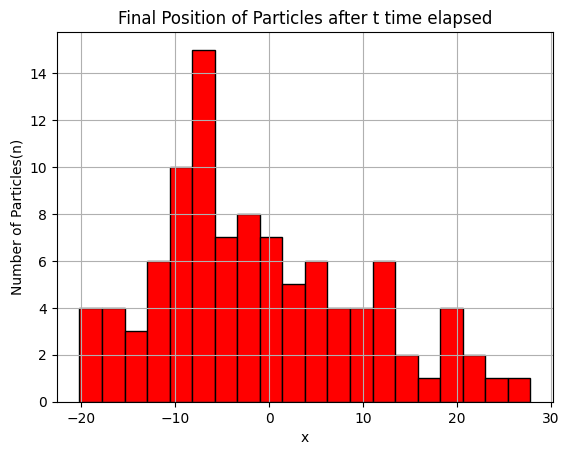

In [ ]:
#Histogram of Final Particle Positions
plt.hist(x_particles, bins=20, color='red', edgecolor='black')
plt.title('Final Position of Particles after t time elapsed')
plt.xlabel('x')
plt.ylabel('Number of Particles(n)')
plt.grid()